In [1]:
from pacha.utils import instruments as iutils
import xarray as xr
from pacha.utils import file_utils as futils
from pacha.visualisation import geospatial as gvis
import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
import numpy as np

In [2]:
def open_daily_funceme(df_paths: pd.DataFrame, date: str):
    xrs = []
    for row in df_paths.loc[date].iterrows():
        ds = xr.open_dataset(row[1].paths)
        t_i = pd.to_datetime(ds.attrs['t_i'])
        t_f = pd.to_datetime(ds.attrs['t_f'])
        t_half = t_i + (t_f - t_i)/2
        ds = ds.assign_coords({'time': t_half})
        xrs.append(ds)

    daily_xr = xr.concat(xrs, 'time')
    return daily_xr


In [3]:
gauges_data_path = '/media/admingosset/T7Shield/data/processed_data/ceara/gauges/v0/gauges_10min_utc.csv'
gauges_metadata_path = '/media/admingosset/T7Shield/data/processed_data/ceara/gauges/v0/gauges_10min_utc_metadata.csv'

gauges = iutils.Gauges(gauges_data_path, gauges_metadata_path)

minimal accepted steps per day (0.8): 115


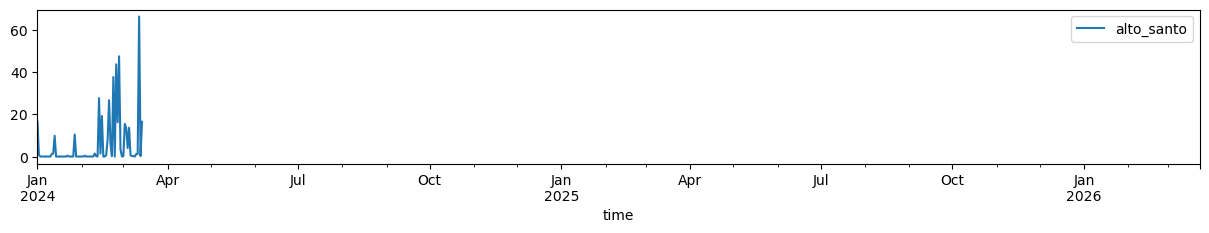

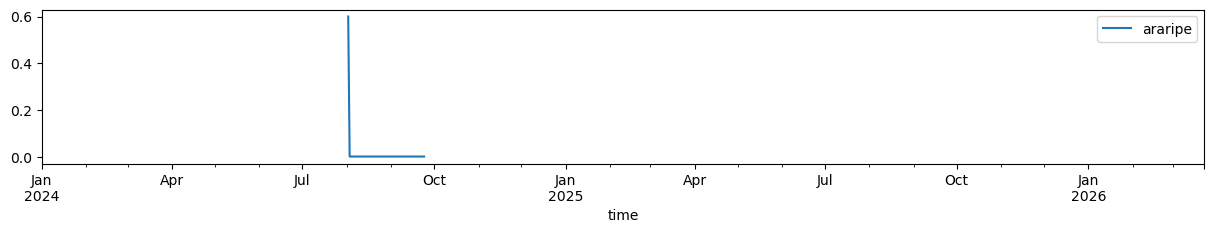

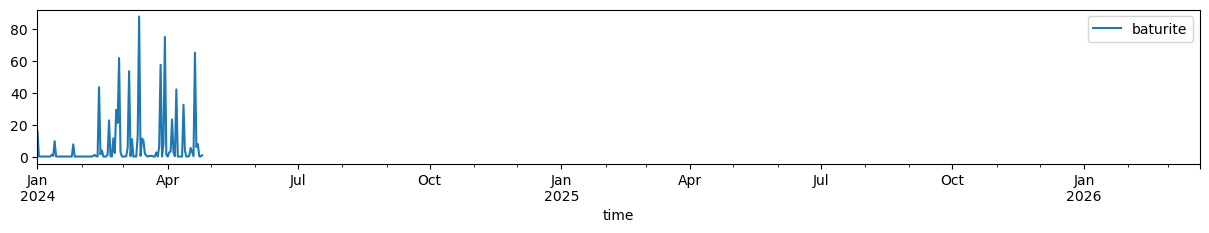

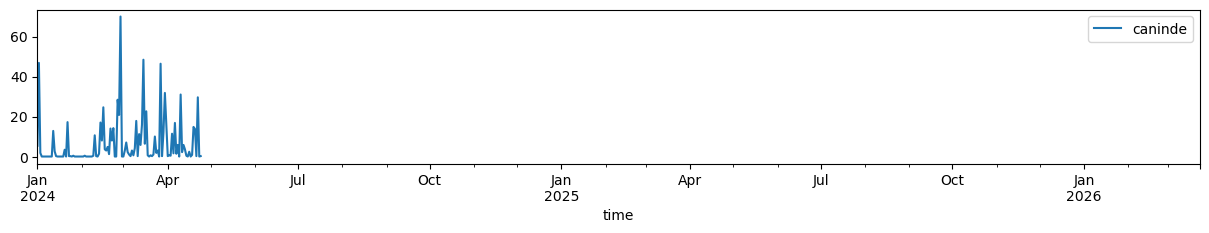

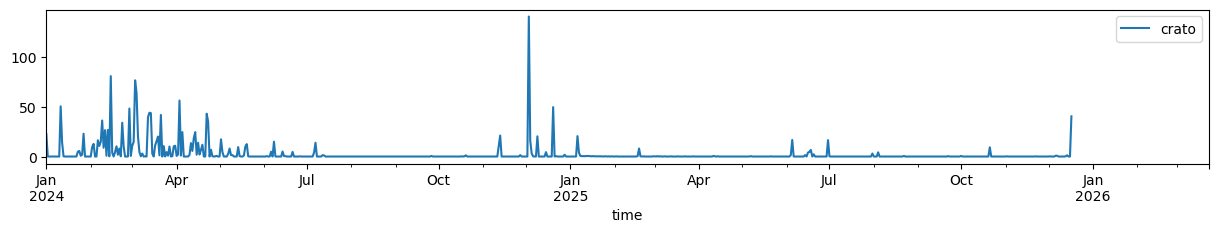

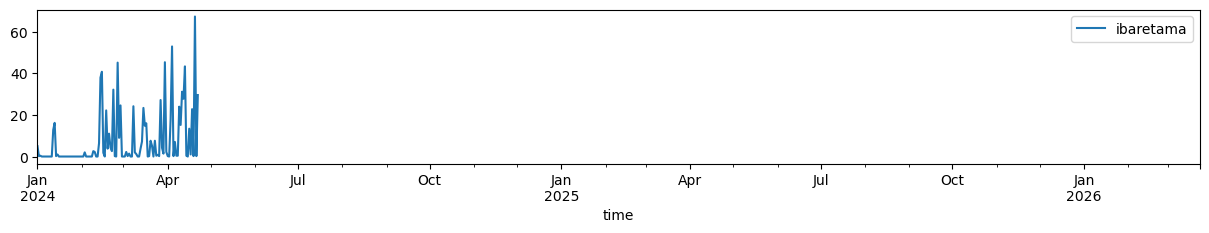

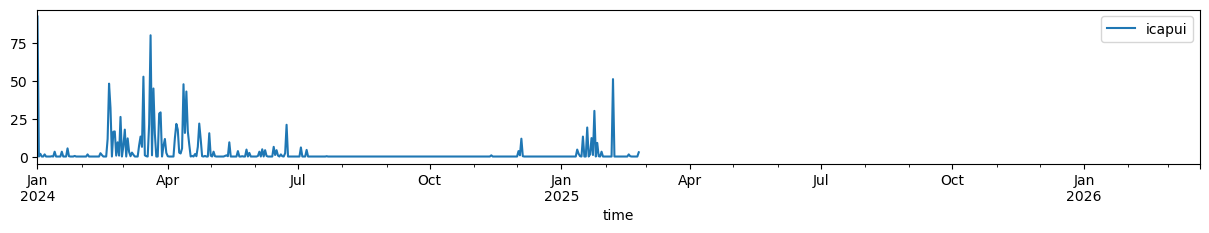

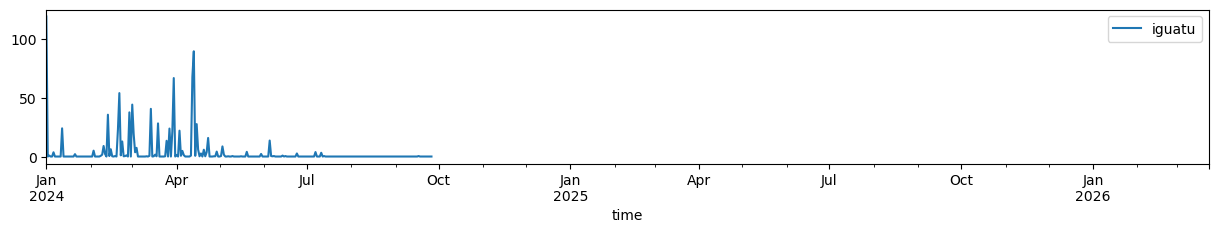

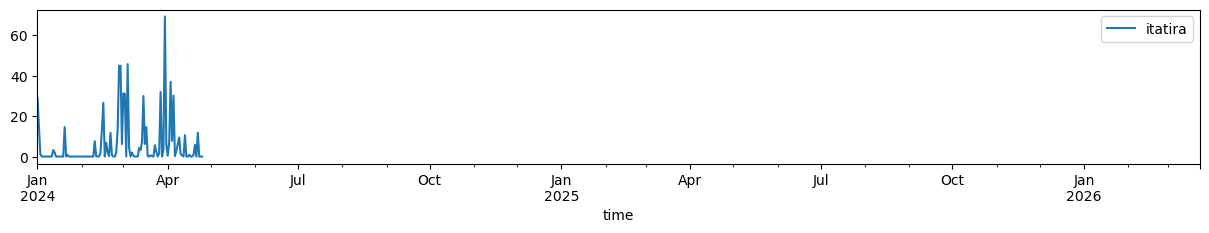

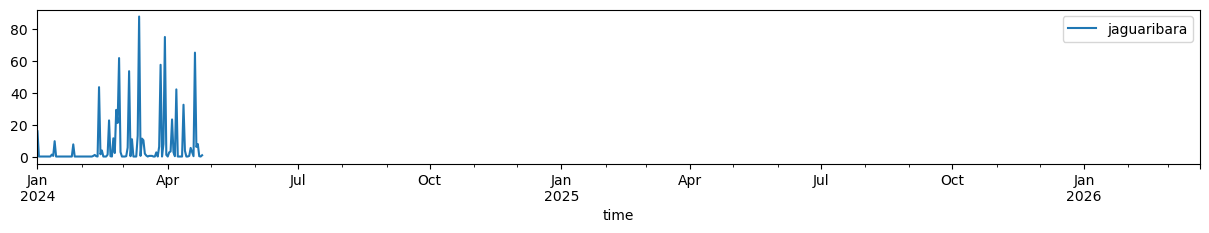

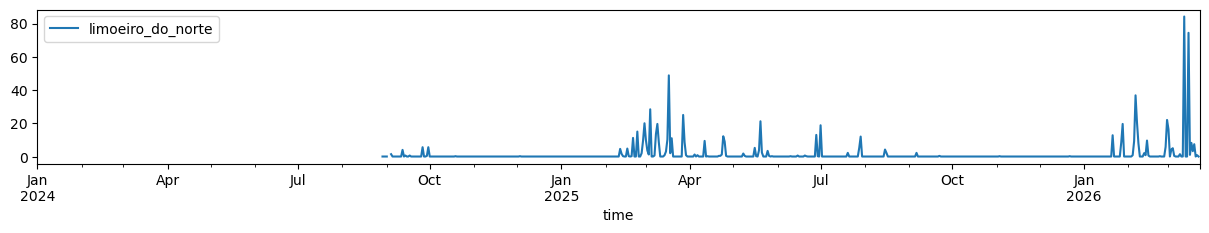

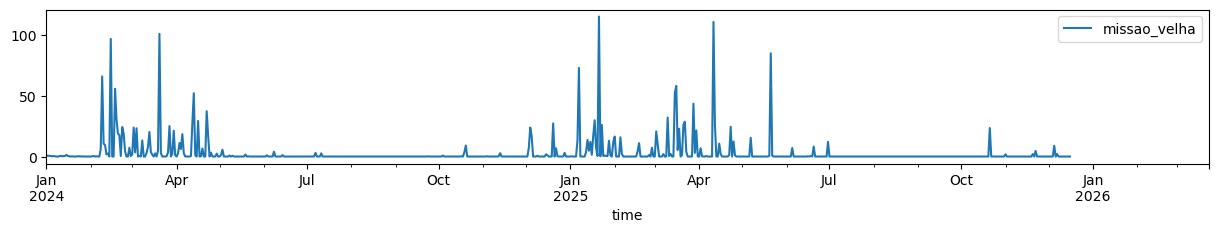

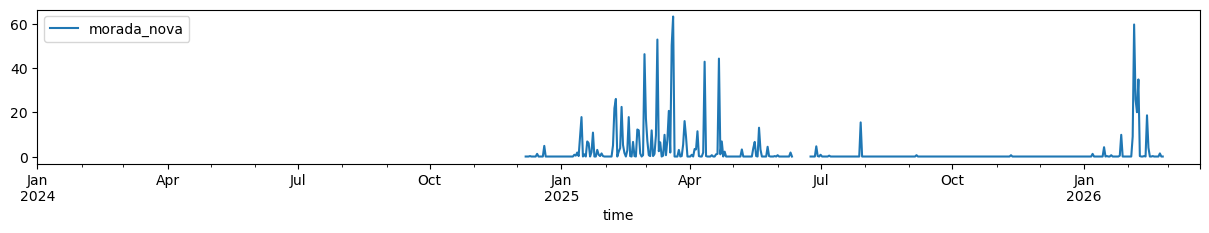

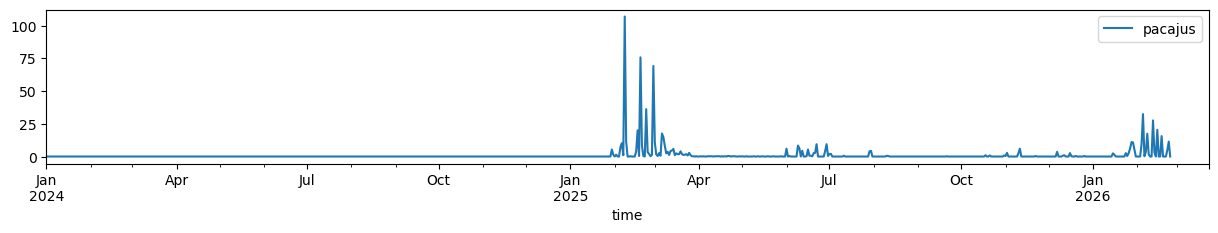

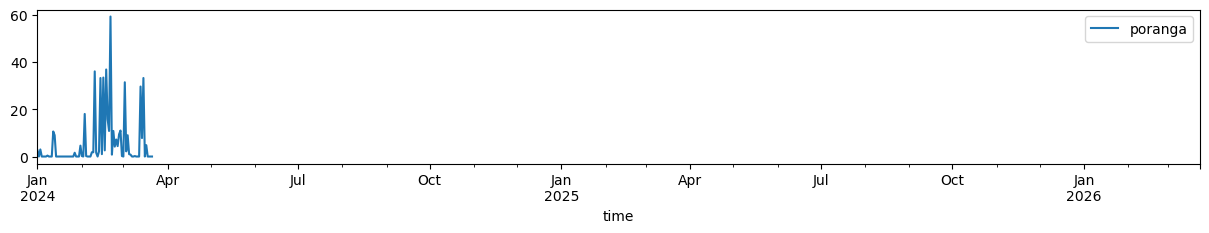

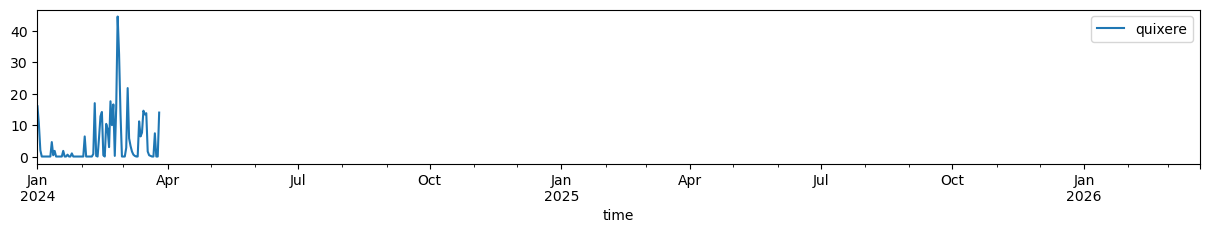

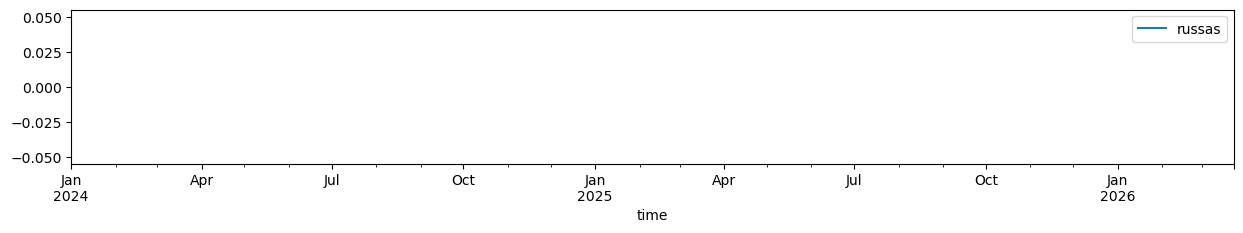

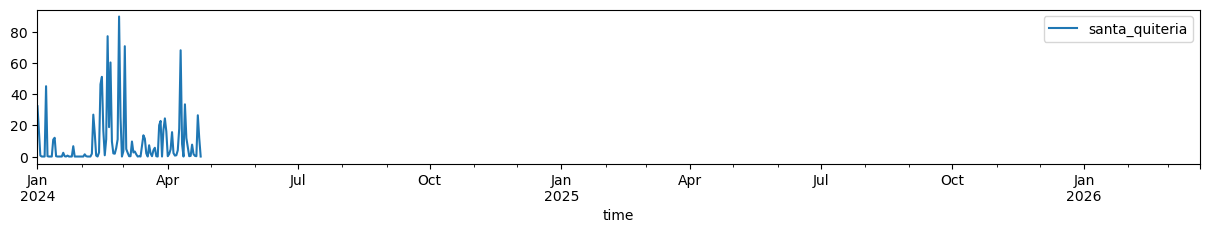

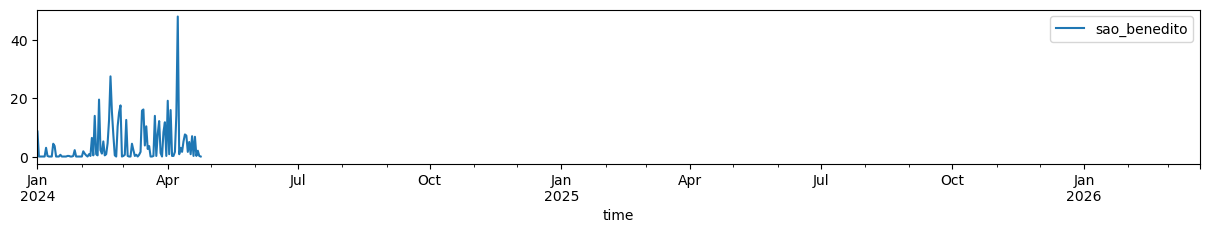

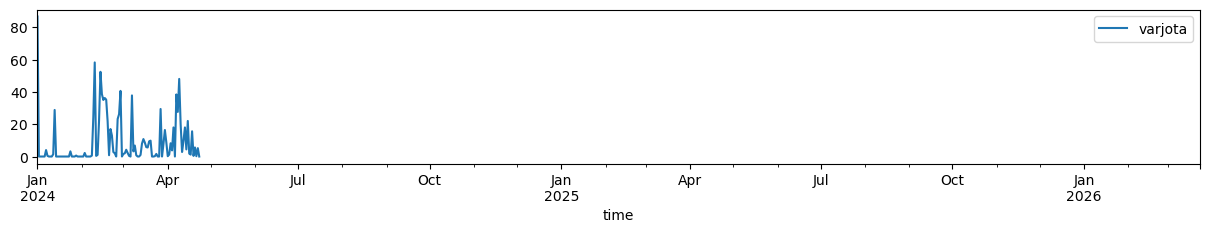

In [4]:
min_steps_per_day = np.int64((24*6)*0.8)

print(f'minimal accepted steps per day (0.8): {min_steps_per_day}')

df_daily_acc = gauges.data.groupby(pd.Grouper(freq='1D')).sum(min_count=min_steps_per_day)

for gauge in gauges.data.columns:
    df_daily_acc.loc['2024':, gauge].plot(label=gauge, figsize=(15,2))
    ax = plt.gca()
    ax.legend()
    plt.show()


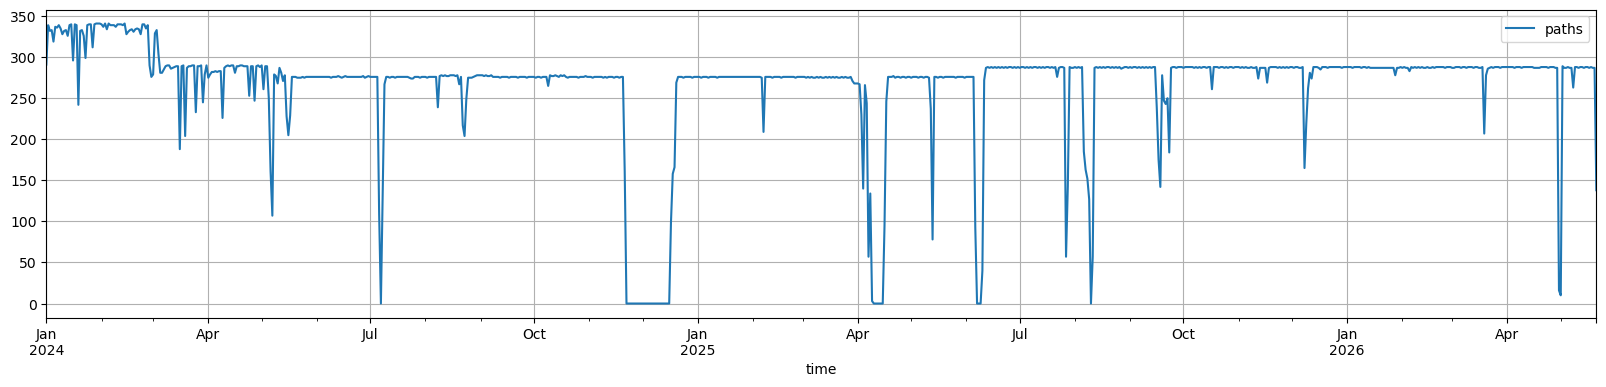

In [5]:
dir_radar = '/media/admingosset/T7Shield/data/raw_data/ceara/ftp_evandro_2026/'

fpaths_rad = futils.get_fpaths_from_dir(dir_radar)

df_fpaths_radar = futils.get_df_dates_filepaths(dir_radar,
                                                date_char_st=4,
                                                date_char_nd=18,
                                                date_format='%Y%m%d%H%M%S')

df_fpaths_radar = df_fpaths_radar.loc['2024':, :]

df_fpaths_radar.groupby(pd.Grouper(freq='1D')).count().plot(figsize=(20,4))
ax = plt.gca()
ax.grid()

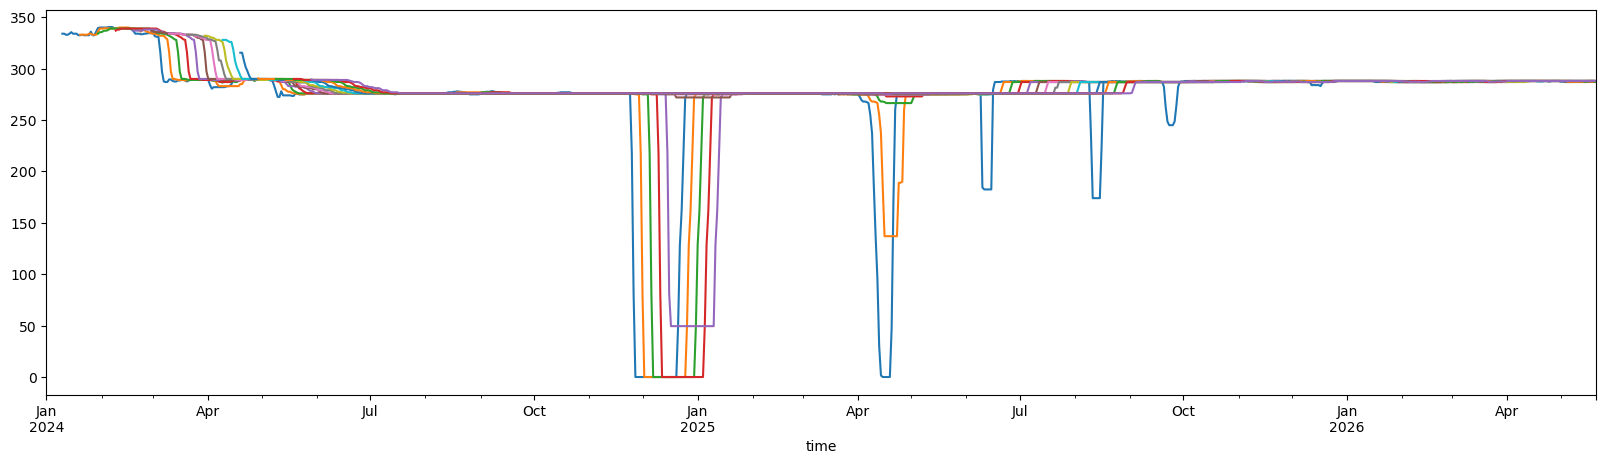

In [6]:
rolling_window = np.int64(np.linspace(10, 150, 15))
fig, ax = plt.subplots(1, 1, figsize=(20,5))
for w in rolling_window:
    df_fpaths_radar.groupby(pd.Grouper(freq='1D')).count().rolling(w).median().plot(ax=ax, legend=False, label=w)

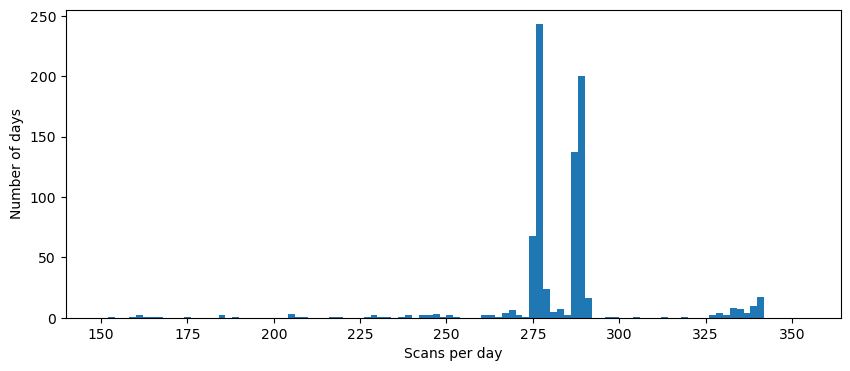

In [7]:
daily = (
    df_fpaths_radar
    .resample('1D')
    .size()
    .rename('n_scans')
)

fig, ax = plt.subplots(figsize=(10, 4))
daily[daily > 150].hist(
    bins=np.arange(150, 355, 2),
    ax=ax
)
ax.set(xlabel='Scans per day', ylabel='Number of days')
ax.grid()
plt.show()

In [8]:
modes = [(270, 280), (282, 300), (325, 350)]

specimens = {}

for i, (low, high) in enumerate(modes, 1):
    subset = daily[(daily > low) & (daily < high)].sort_values()
    specimens[f'mode_{i}'] = subset.index[len(subset) // 2]

for mode, date in specimens.items():
    print(f'{mode}: {date.date()} — {daily.loc[date]} scans')

mode_1: 2024-06-12 — 276 scans
mode_2: 2025-11-22 — 288 scans
mode_3: 2024-01-18 — 339 scans


In [9]:
daily_over_250 = daily.loc[daily>250]

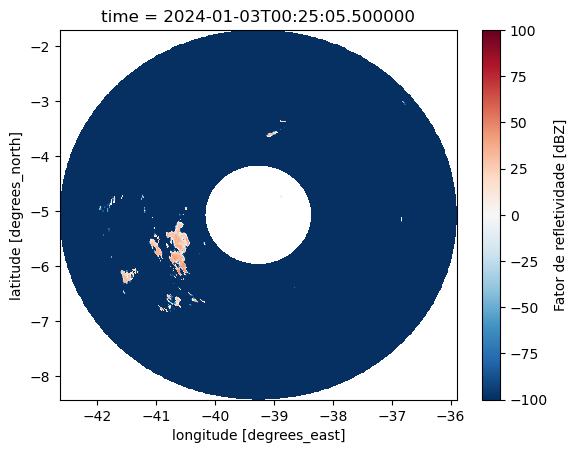

In [ ]:
sample_ds = open_daily_funceme(df_fpaths_radar, str(daily_over_250.index[2].date()))

sample_ds.isel(time=5).dBZ.plot(x='xlon', y='ylat')
fig = plt.gcf()
# fig.savefig(fname='../results/figures/sample_03_01_2024.png')

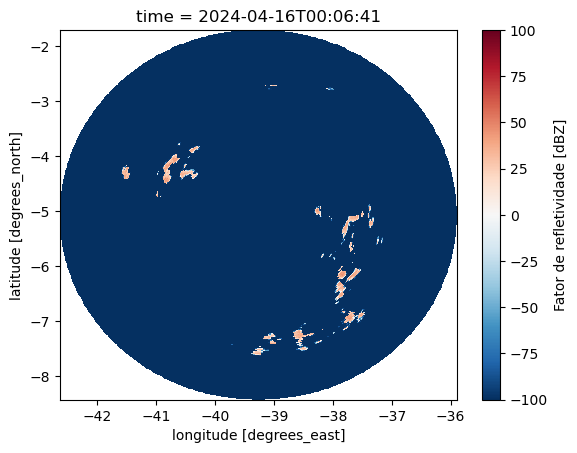

In [11]:
sample_ds = open_daily_funceme(df_fpaths_radar, str(daily_over_250.index[100].date()))

sample_ds.isel(time=0).dBZ.plot(x='xlon', y='ylat')
fig = plt.gcf()
# fig.savefig(fname='../results/figures/sample_16_04_2024.png')

In [12]:
lon0, lat0 = np.median(sample_ds.xlon.values), np.median(sample_ds.ylat.values)

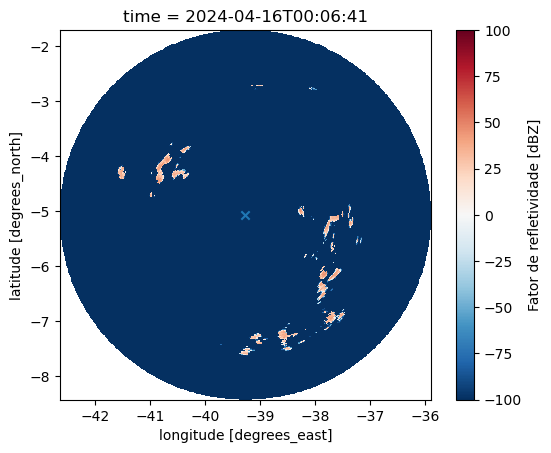

In [13]:
sample_ds.isel(time=0).dBZ.plot(x='xlon', y='ylat')
fig = plt.gcf()
# fig.savefig(fname='../results/figures/sample_16_04_2024.png')
ax = plt.gca()
ax.scatter(lon0, lat0, marker='x')
ax.set_aspect('equal')

In [14]:
gauges.calc_distance_to_point((lat0, lon0))

In [15]:
close_gauges = gauges.metadata.loc[gauges.metadata.distance_to_point < 120]


minimal accepted steps per day (0.8): 115


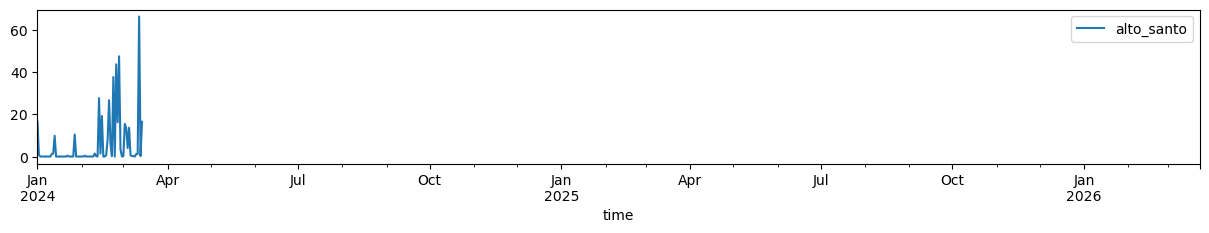

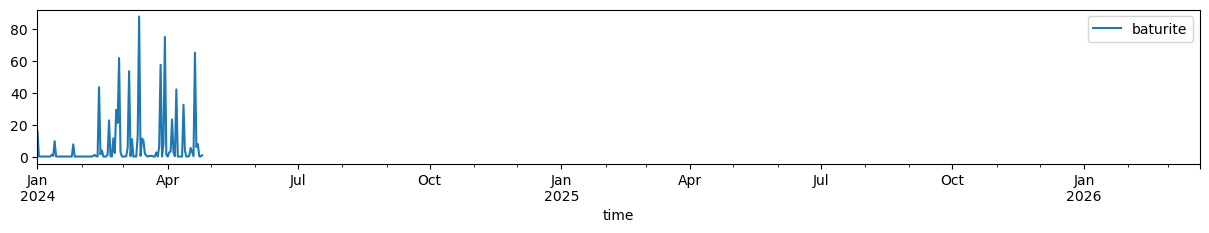

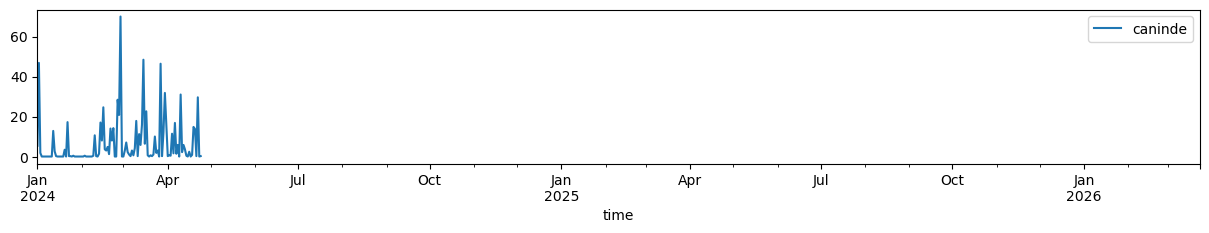

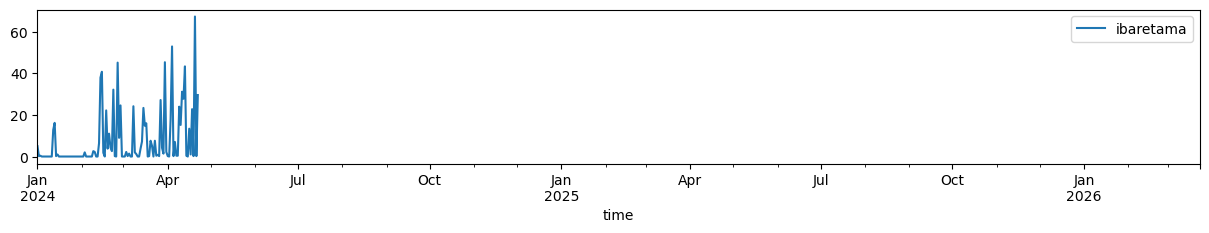

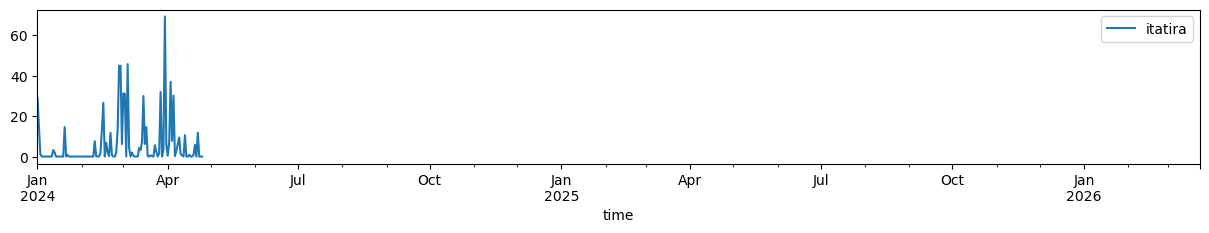

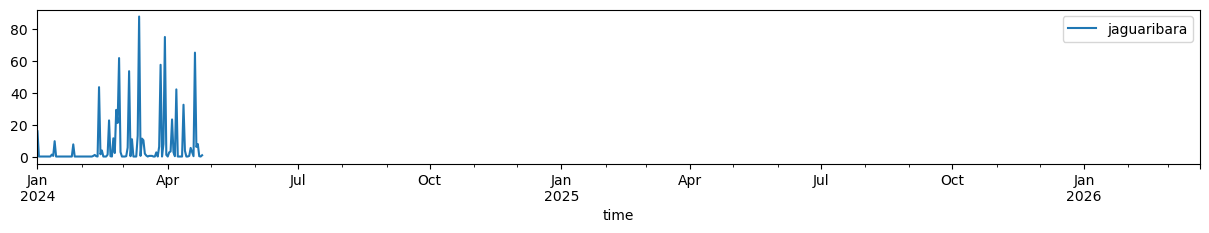

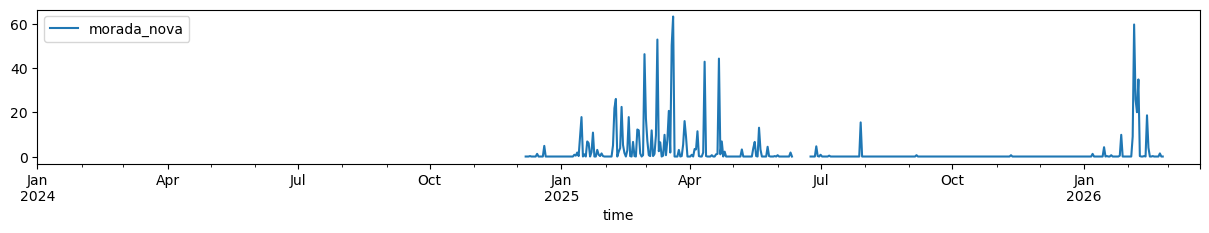

In [16]:
min_steps_per_day = np.int64((24*6)*0.8)

print(f'minimal accepted steps per day (0.8): {min_steps_per_day}')

df_daily_acc = gauges.data.groupby(pd.Grouper(freq='1D')).sum(min_count=min_steps_per_day)

for gauge in close_gauges.index:
    df_daily_acc.loc['2024':, gauge].plot(label=gauge, figsize=(15,2))
    ax = plt.gca()
    ax.legend()
    plt.show()


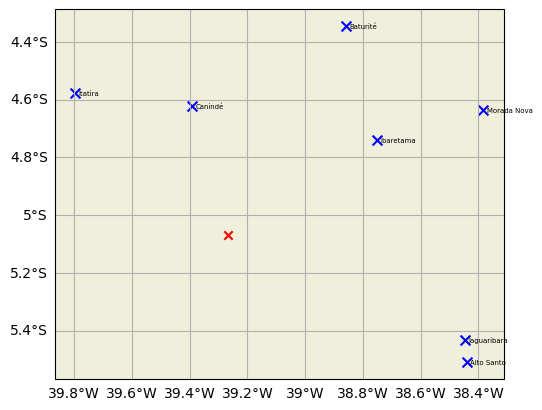

In [17]:
gvis.plot_simple_map()
ax = plt.gca()
gvis.plot_gauge_network(close_gauges, display_names=True)
ax.scatter(lon0, lat0, marker='x', c='r')

In [18]:
close_gauges_data = gauges.data.loc['2024':, close_gauges.index]

In [19]:
close_acc = close_gauges_data.groupby(pd.Grouper(freq='1D')).sum(min_count=min_steps_per_day)

In [20]:
close_acc.loc[(close_acc > 30).sum(axis=1)>=1].shape

(34, 7)

In [21]:
dates = close_acc.loc[(close_acc > 30).sum(axis=1)>=1].index

In [22]:
print(dates)

DatetimeIndex(['2024-01-02', '2024-02-13', '2024-02-14', '2024-02-15',
               '2024-02-23', '2024-02-25', '2024-02-26', '2024-02-27',
               '2024-02-28', '2024-03-01', '2024-03-02', '2024-03-04',
               '2024-03-05', '2024-03-12', '2024-03-15', '2024-03-27',
               '2024-03-30', '2024-04-03', '2024-04-04', '2024-04-05',
               '2024-04-07', '2024-04-10', '2024-04-11', '2024-04-12',
               '2024-04-13', '2024-04-20', '2025-02-28', '2025-03-09',
               '2025-03-19', '2025-03-20', '2025-04-11', '2025-04-21',
               '2026-02-05', '2026-02-08'],
              dtype='datetime64[ns]', name='time', freq=None)


In [28]:
from pacha.L2_processing import radar as l2rad

In [34]:

import numpy as np
import xarray as xr
import dask.array as da
from scipy.spatial import cKDTree, ConvexHull, Delaunay
from pyproj import CRS, Geod, Transformer

def to_lonlat(ds, resolution_m=400, variable="dBZ"):
    """
    Convert variable(time, i, j) to variable(time, lat, lon).

    For a complete circular coordinate grid like test_day.nc.
    Uses nearest-gate sampling, preserves NaNs, and returns lazy data.
    """
    if not np.isfinite(resolution_m) or resolution_m <= 0:
        raise ValueError("resolution_m must be positive and finite.")

    lon = np.asarray(ds.xlon.values, dtype=float)
    lat = np.asarray(ds.ylat.values, dtype=float)
    spatial_dims = ds.xlon.dims

    if (
        lon.ndim != 2
        or lon.shape != lat.shape
        or ds.ylat.dims != spatial_dims
    ):
        raise ValueError("Expected matching static 2-D xlon/ylat.")

    if not (np.isfinite(lon).all() and np.isfinite(lat).all()):
        raise ValueError("This method requires complete geographic coordinates.")

    if set(ds[variable].dims) != {"time", *spatial_dims}:
        raise ValueError("Expected time and two native spatial dimensions.")

    if not np.issubdtype(ds[variable].dtype, np.floating):
        raise TypeError("The variable must have a floating dtype.")

    # Degree spacing corresponding to resolution_m near the radar.
    lon0, lat0 = float(np.median(lon)), float(np.median(lat))
    geod = Geod(ellps="WGS84")
    _, _, dx = geod.inv(lon0, lat0, lon0 + 0.01, lat0)
    _, _, dy = geod.inv(lon0, lat0, lon0, lat0 + 0.01)

    dlon = resolution_m / (dx / 0.01)
    dlat = resolution_m / (dy / 0.01)

    out_lon = lon.min() + np.arange(int(np.ptp(lon) / dlon) + 1) * dlon
    out_lat = lat.min() + np.arange(int(np.ptp(lat) / dlat) + 1) * dlat
    ny, nx = len(out_lat), len(out_lon)

    if ny * nx > 25_000_000:
        raise ValueError("Target grid is too large; increase resolution_m.")

    # Find nearest gates using distances in metres.
    local_crs = CRS.from_proj4(
        f"+proj=aeqd +lat_0={lat0} +lon_0={lon0} "
        "+datum=WGS84 +units=m"
    )
    project = Transformer.from_crs(
        "EPSG:4326", local_crs, always_xy=True
    )

    sx, sy = project.transform(lon.ravel(), lat.ravel())
    source_points = np.column_stack([sx, sy])

    target_lon, target_lat = np.meshgrid(out_lon, out_lat)
    tx, ty = project.transform(target_lon.ravel(), target_lat.ravel())
    target_points = np.column_stack([tx, ty])

    _, nearest = cKDTree(source_points).query(target_points)

    # Mask points outside the radar footprint.
    hull = ConvexHull(source_points)
    inside = (
        Delaunay(source_points[hull.vertices])
        .find_simplex(target_points) >= 0
    )

    # Read native time chunks, then remap one timestep per block.
    field = ds[variable].transpose("time", *spatial_dims)
    native_chunks = field.encoding.get("chunksizes")
    read_chunk = native_chunks[0] if native_chunks else 1

    data = field.chunk({
        "time": read_chunk,
        spatial_dims[0]: -1,
        spatial_dims[1]: -1,
    }).data.rechunk({0: 1})

    def remap(block):
        values = block.reshape(block.shape[0], -1)[:, nearest].copy()
        values[:, ~inside] = np.nan
        return values.reshape(block.shape[0], ny, nx)

    mapped = da.map_blocks(
        remap,
        data,
        dtype=field.dtype,
        chunks=(data.chunks[0], (ny,), (nx,)),
        drop_axis=(1, 2),
        new_axis=(1, 2),
        meta=np.empty((0, 0, 0), dtype=field.dtype),
    )

    result = xr.Dataset(
        {variable: (
            ("time", "lat", "lon"), mapped, dict(field.attrs)
        )},
        coords={"time": ds.time, "lat": out_lat, "lon": out_lon},
        attrs=dict(ds.attrs),
    )

    result.lon.attrs = {
        "standard_name": "longitude", "units": "degrees_east", "axis": "X"
    }
    result.lat.attrs = {
        "standard_name": "latitude", "units": "degrees_north", "axis": "Y"
    }
    result.attrs.update(
        nominal_grid_spacing_m=float(resolution_m),
        regridding="nearest native gate; source NaNs retained",
    )

    # These original global bounds describe only the first scan.
    for name in ["t_i", "t_f"]:
        if name in result.attrs:
            result.attrs[f"source_first_scan_{name}"] = result.attrs.pop(name)

    return result

In [42]:
geo_ds = to_lonlat(sample_ds, resolution_m=1000)

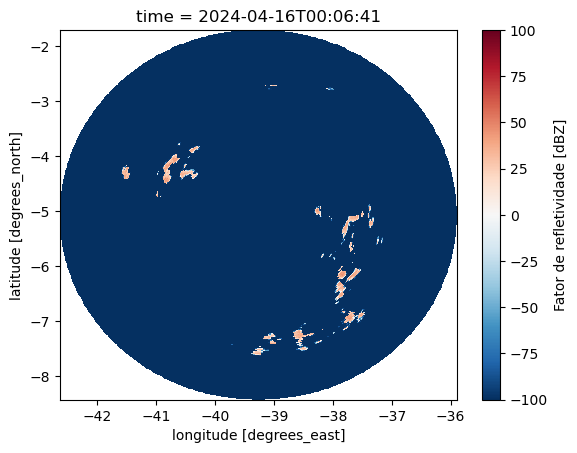

In [39]:
sample_ds.isel(time=0).dBZ.plot(x='xlon', y='ylat')

In [40]:
gauges.get_coords_station(close_gauges.index[0])

(np.float64(-38.4405), np.float64(-5.509194))

<Axes: xlabel='time'>

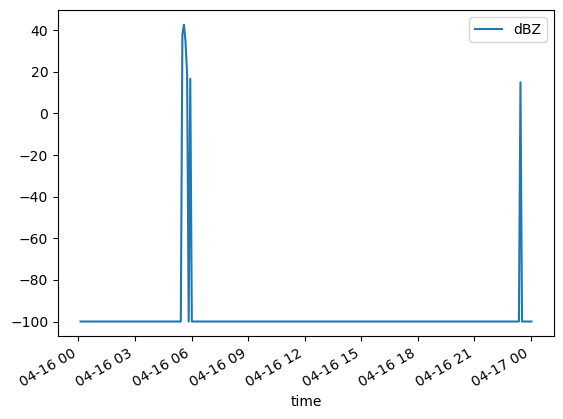

In [53]:
from pacha.utils import geospatial as gutils
gutils.ds_to_df_at_point(geo_ds, gauges.get_coords_station(close_gauges.index[3])).plot()

<Axes: xlabel='time'>

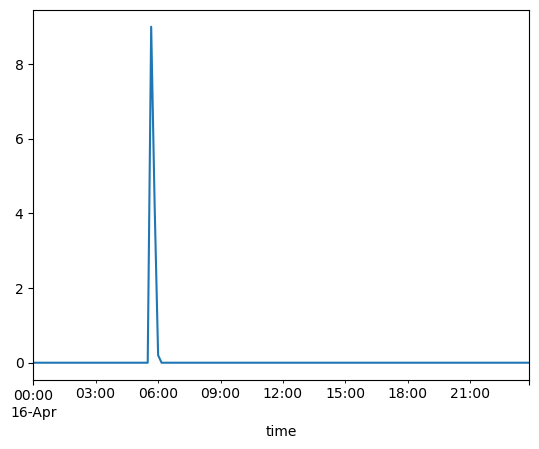

In [60]:
gauges.data.loc['2024-04-16', close_gauges.index[3]].plot(legend=False)

In [61]:
close_gauges

,lat,lon,alt,name,distance_to_point
id,,,,,
alto_santo,-5.509194,-38.440500,102,Alto Santo,103.829685
baturite,-4.345528,-38.857500,168,Baturité,92.302002
caninde,-4.621694,-39.392778,280,Canindé,51.573539
ibaretama,-4.740139,-38.749661,103,Ibaretama,67.956665
itatira,-4.575472,-39.796194,413,Itatira,80.245133
jaguaribara,-5.433742,-38.444814,141,Jaguaribara,99.710347
morada_nova,-4.636111,-38.383056,84,Morada Nova,109.105795
